# 03 · Les couleurs des Pokémon à partir de leurs images

Dans PokéAPI chaque Pokémon a **une seule couleur officielle** (`couleur` dans la table maître). C'est pratique mais très grossier : Dracaufeu est « rouge » alors qu'il est orange avec du bleu et du crème.

L'idée ici c'est de repartir des **images officielles** (artwork) et de calculer nous-mêmes :
- combien de couleurs « importantes » a chaque Pokémon ;
- quelle est sa couleur dominante ;
- quelle part du corps prend chaque couleur.

Pour ça on utilise le **k-means** du TP2, mais sur les pixels d'une image : chaque pixel est un point (R, V, B) et on regroupe les pixels qui ont une couleur proche. Le centre de chaque groupe, c'est une couleur de la palette du Pokémon.

La démarche : on découvre d'abord les images, on enlève le fond, on choisit le nombre de groupes du k-means sur quelques exemples, on fusionne les nuances d'une même couleur, on enlève le contour noir du dessin, puis on applique tout ça aux 1 025 Pokémon. À la fin on compare avec la couleur officielle et on regarde l'évolution au fil des générations.

In [1]:
from pathlib import Path
import colorsys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score

IMG = Path("../data/raw/sprites/official_artwork")
OUT = Path("../data/processed")
table = pd.read_csv(OUT / "table_maitre.csv", index_col="dex")
nom = table["nom_fr"]

## 1. Découverte des images

In [2]:
fichiers = sorted(IMG.glob("*.png"), key=lambda p: int(p.stem))
print(len(fichiers), "images")
infos = []
for p in fichiers:
    im = Image.open(p)
    infos.append((int(p.stem), im.size, im.mode))
infos = pd.DataFrame(infos, columns=["dex", "taille", "mode"]).set_index("dex")
print(infos["taille"].value_counts())
print(infos["mode"].value_counts())

1025 images


taille
(475, 475)    1025
Name: count, dtype: int64
mode
RGBA    1025
Name: count, dtype: int64


Les 1 025 images sont toutes au même format : 475 × 475 pixels, en mode RGBA (rouge, vert, bleu + transparence).

In [3]:
# est-ce qu'il manque des numéros ?
set(range(1, 1026)) - set(infos.index)

set()

Il ne manque aucun numéro.

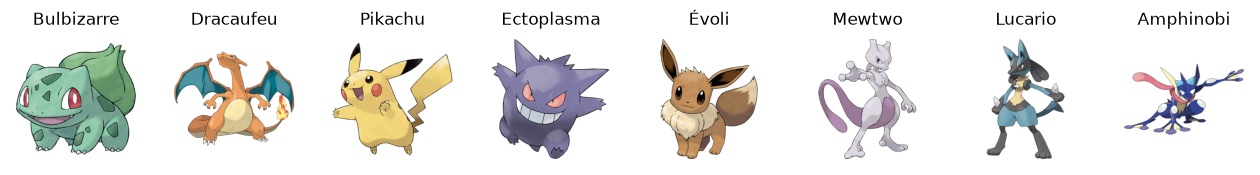

In [4]:
exemples = [1, 6, 25, 94, 133, 150, 448, 658]
fig, axes = plt.subplots(1, len(exemples), figsize=(16, 2.5))
for ax, d in zip(axes, exemples):
    ax.imshow(Image.open(IMG / f"{d}.png"))
    ax.set_title(nom[d])
    ax.axis("off")
plt.show()

On voit que tous les dessins ont le même style : un fond transparent, des aplats de couleur avec des ombres, et **un contour sombre** autour du Pokémon et de ses détails. On reviendra sur ce contour plus bas.

Le fond transparent, c'est le 4e canal (alpha) du mode RGBA. Un pixel avec alpha = 0 est invisible, il ne faut pas le compter comme une couleur. On regarde quelle part de l'image est transparente, et s'il y a des valeurs d'alpha entre 0 et 255 (les bords adoucis).

In [5]:
def alpha(d):
    return np.asarray(Image.open(IMG / f"{d}.png").convert("RGBA"))[..., 3]

a = alpha(25)
print("Pikachu : part de pixels totalement transparents =", round((a == 0).mean(), 3))
print("part de pixels semi-transparents (entre 1 et 254) =", round(((a > 0) & (a < 255)).mean(), 4))

Pikachu : part de pixels totalement transparents = 0.648
part de pixels semi-transparents (entre 1 et 254) = 0.0153


Sur Pikachu, 65 % de l'image est totalement transparente, et 1,5 % des pixels sont semi-transparents : ce sont les bords adoucis du dessin, dont la couleur est mélangée avec le fond.

Du coup on décide de ne garder que les pixels **assez opaques, avec alpha ≥ 128** (la moitié de 255). Ça enlève le fond et la plupart des bords adoucis, qui ne sont pas de vraies couleurs du Pokémon. On perd un peu de bord, mais c'est très peu de pixels.

In [6]:
SEUIL_ALPHA = 128

# part de pixels visibles sur toutes les images
part_visible = pd.Series({d: (alpha(d) >= SEUIL_ALPHA).mean() for d in infos.index}, name="part_visible")
part_visible.describe()

count    1025.000000
mean        0.313141
std         0.092918
min         0.097711
25%         0.248049
50%         0.303291
75%         0.368182
max         0.636242
Name: part_visible, dtype: float64

In [7]:
pd.concat([part_visible, nom], axis=1).sort_values("part_visible").iloc[[0, 1, 2, -3, -2, -1]]

,part_visible,nom_fr
973,0.097711,Flamenroule
283,0.102564,Arakdo
960,0.105316,Taupikeau
517,0.624625,Munna
577,0.627918,Nucléos
101,0.636242,Électrode


En moyenne le Pokémon occupe 31 % de l'image. Ça va de 10 % pour les Pokémon fins ou allongés (Flamenroule, Arakdo, Taupikeau) à 64 % pour les Pokémon ronds (Électrode, Nucléos, Munna). Même dans le pire cas il reste plus de 20 000 pixels visibles.

Faire un k-means sur ~70 000 pixels pour chacun des 1 025 Pokémon serait très long. Comme on cherche juste les grandes zones de couleur, on décide de **tirer au hasard 3 000 pixels visibles par image** : c'est largement assez pour qu'une couleur qui couvre quelques pour cent du corps soit bien représentée (5 % de 3 000 = 150 pixels). On fixe la graine du hasard pour que les résultats soient les mêmes à chaque exécution, et on donne à **chaque Pokémon son propre tirage** (la graine combinée à son numéro) : comme ça, un Pokémon a toujours les mêmes 3 000 pixels, même si on relance une seule cellule ou si on ajoute un exemple avant la boucle sur les 1 025 Pokémon.

In [8]:
N_PIXELS = 3000
SEED = 0

def pixels(d, n=N_PIXELS):
    # un générateur par Pokémon, à partir de la graine et du numéro : un Pokémon a toujours
    # les mêmes pixels, quel que soit l'ordre dans lequel on exécute les cellules
    rng = np.random.default_rng([SEED, d])
    arr = np.asarray(Image.open(IMG / f"{d}.png").convert("RGBA")).reshape(-1, 4)
    vis = arr[arr[:, 3] >= SEUIL_ALPHA, :3]
    if len(vis) > n:
        vis = vis[rng.choice(len(vis), n, replace=False)]
    return vis.astype(float)

pixels(25).shape

(3000, 3)

### Ce qu'on a fait et pourquoi

**1. Le canal alpha pour enlever le fond.** Les images sont en RGBA : le fond est transparent. On ne garde que les pixels assez opaques (alpha ≥ 128, la moitié) parce qu'un pixel transparent n'est pas une couleur du Pokémon, et que les bords à moitié transparents ont une couleur mélangée avec le fond. Couper à la moitié, c'est le choix le plus neutre : on garde ce qui est « plus Pokémon que fond ».

**2. Un échantillon de pixels plutôt que tous.** On tire 3 000 pixels visibles au hasard par image au lieu de les prendre tous, sinon le k-means sur 1 025 images serait très long. Comme on cherche les grandes zones de couleur, un échantillon suffit : une couleur qui couvre quelques pour cent du corps a encore une centaine de pixels. On fixe la graine pour que les résultats ne changent pas d'une exécution à l'autre. Au départ on utilisait un seul générateur pour tout le notebook : les pixels tirés pour un Pokémon dépendaient alors de tous les tirages faits avant lui, et relancer une cellule au milieu (ou ajouter un exemple) changeait les résultats. On a donc donné à chaque Pokémon son propre générateur (graine + numéro).

## 2. Combien de groupes pour le k-means ?

Comme au TP2, on fait tourner le k-means pour k = 2 à 12 sur trois exemples et on regarde :
- **l'inertie** (somme des distances au centre) : elle baisse toujours quand k augmente, on cherche le « coude » où elle arrête de baisser beaucoup ;
- **la silhouette** : entre -1 et 1, plus elle est haute plus les groupes sont bien séparés.

On prend Pikachu (simple, jaune), Dracaufeu (plusieurs couleurs) et Ectoplasma (presque une seule couleur).

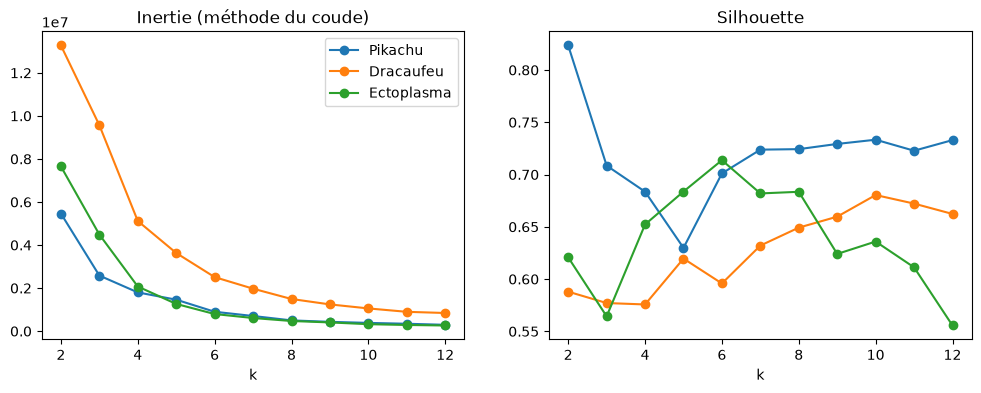

In [9]:
ks = range(2, 13)
res = {}
for d in [25, 6, 94]:
    X = pixels(d)
    inert, sil = [], []
    for k in ks:
        km = KMeans(n_clusters=k, n_init=3, random_state=SEED).fit(X)
        inert.append(km.inertia_)
        sil.append(silhouette_score(X, km.labels_))
    res[nom[d]] = (inert, sil)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for n, (inert, sil) in res.items():
    axes[0].plot(list(ks), inert, marker="o", label=n)
    axes[1].plot(list(ks), sil, marker="o", label=n)
axes[0].set(title="Inertie (méthode du coude)", xlabel="k")
axes[1].set(title="Silhouette", xlabel="k")
axes[0].legend(); plt.show()

In [10]:
pd.DataFrame({n: sil for n, (_, sil) in res.items()}, index=list(ks)).round(3)

,Pikachu,Dracaufeu,Ectoplasma
2,0.823,0.588,0.621
3,0.709,0.577,0.564
4,0.684,0.576,0.652
5,0.630,0.620,0.684
6,0.701,0.596,0.714
7,0.724,0.632,0.682
8,0.724,0.649,0.684
9,0.729,0.660,0.624
10,0.733,0.680,0.636
11,0.723,0.672,0.611


L'inertie baisse beaucoup jusqu'à k = 4 environ puis de moins en moins, mais il n'y a pas de coude net. Et la silhouette ne donne pas le même k selon le Pokémon : k = 2 pour Pikachu (0,82), k = 6 pour Ectoplasma (0,71), k = 10 pour Dracaufeu (0,68). Il n'y a donc **pas un k qui marche pour tout le monde**.

Chercher le meilleur k pour chacun des 1 025 Pokémon serait long et pas très stable. On choisit plutôt de prendre **un k assez grand pour tout le monde, k = 8**, pour être sûr de ne rater aucune couleur même chez les Pokémon chargés, et de **regrouper ensuite les nuances trop proches** (partie 3). Avec k = 8, la silhouette est déjà bonne pour les trois exemples (0,65 à 0,72).

On voit ce que ça donne sur Dracaufeu, avec k = 3 et k = 8. Chaque barre est une couleur, sa largeur = la part des pixels.

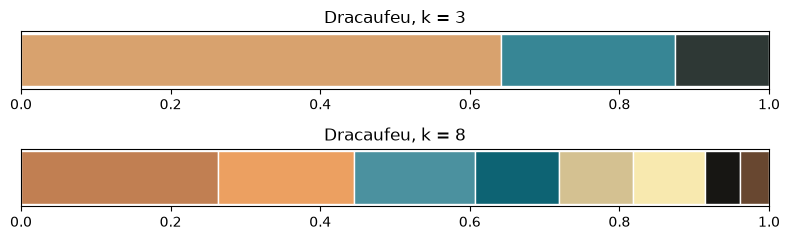

In [11]:
K = 8

def palette(X, k=K):
    km = KMeans(n_clusters=k, n_init=3, random_state=SEED).fit(X)
    parts = np.bincount(km.labels_, minlength=k) / len(X)
    return km.cluster_centers_, parts, km.labels_

def dessine(ax, centres, parts, titre=""):
    x = 0
    for i in np.argsort(-parts):
        ax.barh(0, parts[i], left=x, color=np.clip(centres[i], 0, 255) / 255, edgecolor="white")
        x += parts[i]
    ax.set(xlim=(0, 1), yticks=[], title=titre)

X = pixels(6)
fig, axes = plt.subplots(2, 1, figsize=(8, 2.5))
for ax, k in zip(axes, [3, 8]):
    c, p, _ = palette(X, k)
    dessine(ax, c, p, f"Dracaufeu, k = {k}")
plt.tight_layout(); plt.show()

Avec k = 3 le k-means mélange des couleurs différentes. Avec k = 8 on retrouve bien l'orange, le bleu des ailes, le crème du ventre et le contour noir, mais l'orange, le bleu et le crème sont coupés en deux nuances (clair / ombre). C'est ce qu'on règle maintenant.

## 3. Fusionner les nuances d'une même couleur

Avec k = 8, le k-means découpe souvent une même couleur en plusieurs nuances : la partie éclairée, la partie dans l'ombre… Bulbizarre aurait alors 4 ou 5 « couleurs » qui sont toutes du vert. Ce n'est pas ce qu'on veut compter.

Donc après le k-means, on regroupe les centres trop proches. Pour mesurer la distance entre deux couleurs, on passe dans l'**espace Lab** : c'est un espace fait pour que la distance corresponde à peu près à la différence que voit l'œil (en RGB, deux couleurs à la même distance peuvent paraître très proches ou très différentes). Dans Lab, **L\*** c'est la clarté (0 = noir, 100 = blanc), et a\*, b\* donnent la teinte. La distance entre deux couleurs s'appelle le **ΔE** : autour de 2 on voit à peine la différence, au-delà de 20-30 ce sont des couleurs nettement différentes.

On regroupe les centres avec une classification hiérarchique (lien moyen, comme la CAH du TP2) coupée à un seuil de ΔE. La couleur d'un groupe fusionné est la moyenne de ses nuances, pondérée par leur part. On essaie trois seuils sur quatre exemples.

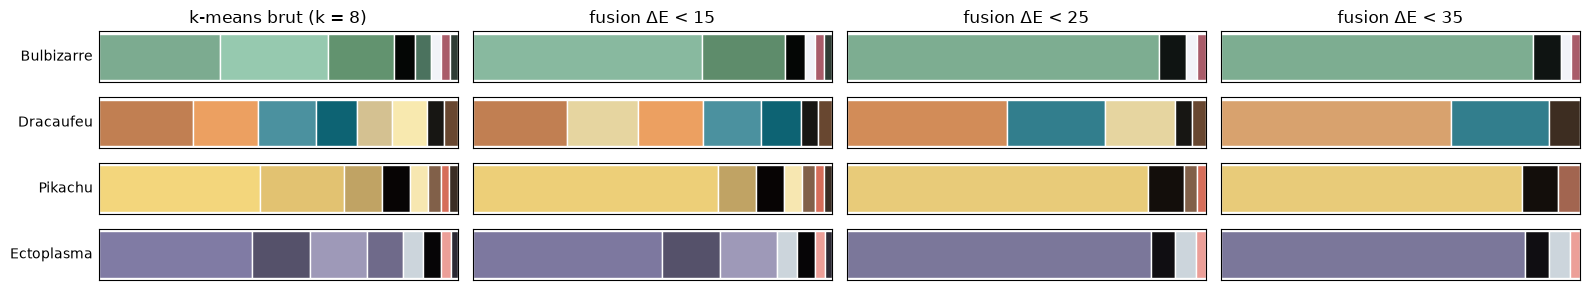

,ΔE < 15,ΔE < 25,ΔE < 35
Bulbizarre,6,4,4
Dracaufeu,7,5,3
Pikachu,7,4,3
Ectoplasma,7,4,4


In [12]:
def rgb_vers_lab(rgb):
    # rgb entre 0 et 255 -> Lab (illuminant D65), formule standard
    c = np.asarray(rgb, dtype=float) / 255
    c = np.where(c > 0.04045, ((c + 0.055) / 1.055) ** 2.4, c / 12.92)
    M = np.array([[0.4124, 0.3576, 0.1805], [0.2126, 0.7152, 0.0722], [0.0193, 0.1192, 0.9505]])
    xyz = c @ M.T / np.array([0.95047, 1.0, 1.08883])
    f = np.where(xyz > 0.008856, np.cbrt(xyz), 7.787 * xyz + 16 / 116)
    return np.stack([116 * f[..., 1] - 16, 500 * (f[..., 0] - f[..., 1]), 200 * (f[..., 1] - f[..., 2])], axis=-1)

def fusion(centres, parts, seuil):
    # renvoie les couleurs fusionnées (de la plus grande à la plus petite), leurs parts,
    # et pour chaque groupe du k-means le numéro de la couleur fusionnée où il est rangé
    groupes = AgglomerativeClustering(n_clusters=None, distance_threshold=seuil,
                                      linkage="average").fit_predict(rgb_vers_lab(centres))
    uniques = np.unique(groupes)
    nc = np.array([(centres[groupes == g] * parts[groupes == g, None]).sum(0) / parts[groupes == g].sum() for g in uniques])
    np_ = np.array([parts[groupes == g].sum() for g in uniques])
    ordre = np.argsort(-np_)
    rang = np.empty(len(uniques), dtype=int); rang[ordre] = np.arange(len(uniques))
    return nc[ordre], np_[ordre], rang[np.searchsorted(uniques, groupes)]

ex = [1, 6, 25, 94]
pal_ex = {d: palette(pixels(d)) for d in ex}
seuils = [15, 25, 35]
fig, axes = plt.subplots(len(ex), 1 + len(seuils), figsize=(16, 3))
for ligne, d in zip(axes, ex):
    c, p, _ = pal_ex[d]
    dessine(ligne[0], c, p)
    for ax, s in zip(ligne[1:], seuils):
        fc, fp, _ = fusion(c, p, s)
        dessine(ax, fc, fp)
    ligne[0].set_ylabel(nom[d], rotation=0, ha="right", va="center")
    for ax in ligne: ax.set_xticks([])
axes[0, 0].set_title(f"k-means brut (k = {K})")
for ax, s in zip(axes[0, 1:], seuils): ax.set_title(f"fusion ΔE < {s}")
plt.tight_layout(); plt.show()
pd.DataFrame({f"ΔE < {s}": [len(fusion(*pal_ex[d][:2], s)[0]) for d in ex] for s in seuils}, index=[nom[d] for d in ex])

On voit que :
- à **15**, il reste encore plusieurs nuances de vert chez Bulbizarre et de violet chez Ectoplasma ;
- à **35**, on commence à mélanger des couleurs vraiment différentes : le crème du ventre de Dracaufeu disparaît dans son orange, et le rouge des joues de Pikachu dans le brun ;
- à **25**, les verts de Bulbizarre, les jaunes de Pikachu et les violets d'Ectoplasma deviennent une seule couleur, Dracaufeu garde bien son orange, son bleu et son crème, et Pikachu ses joues rouges.

On garde donc **ΔE < 25**, ce qui colle aussi avec l'ordre de grandeur « au-delà de 20-30, deux couleurs sont nettement différentes ».

Par contre il reste un problème : le **contour noir** du dessin ressort comme une couleur à part chez presque tous les Pokémon.

In [13]:
FUSION_DELTA_E = 25

### Ce qu'on a fait et pourquoi (parties 2 et 3)

**1. Le k-means sur les pixels.** On a utilisé le k-means du TP2, mais en prenant chaque pixel comme un point en 3 dimensions (rouge, vert, bleu). Les centres des groupes sont les couleurs de la palette, et la taille de chaque groupe donne la part du corps de chaque couleur. C'est la méthode la plus simple pour résumer une image en quelques couleurs, et elle marche bien ici parce que les dessins sont faits d'aplats.

**2. Le coude et la silhouette pour choisir k.** Comme au TP2, on a tracé l'inertie (méthode du coude) et la silhouette pour k de 2 à 12 sur trois Pokémon très différents (un simple, un très coloré, un presque d'une seule couleur). Les deux critères ne donnent pas le même k selon le Pokémon, donc on n'a pas cherché le « meilleur k » pour chacun : ça aurait été long et instable. On a pris un **k assez grand pour tout le monde (k = 8)**, pour ne rater aucune couleur chez les Pokémon chargés, quitte à couper une couleur en plusieurs nuances, qu'on regroupe juste après.

**3. Les barres de palette pour montrer le résultat.** Pour voir ce que donne le k-means, on dessine chaque palette comme une barre découpée : une couleur par morceau, la largeur = la part des pixels. C'est plus parlant qu'un tableau de codes couleur, on voit directement si le k-means coupe une couleur en deux.

**4. Passer en Lab pour mesurer l'écart entre deux couleurs.** Pour savoir si deux centres sont « la même couleur », on ne compare pas les valeurs RGB : en RGB, deux couleurs à la même distance peuvent paraître presque pareilles ou très différentes à l'œil. L'espace Lab est fait pour que la distance (le ΔE) corresponde à ce que voit l'œil, donc c'est le bon espace pour fusionner des nuances.

**5. Une CAH sur les centres, coupée à un seuil.** On regroupe les centres trop proches avec une classification hiérarchique (lien moyen, comme au TP2), coupée à un seuil de ΔE plutôt qu'à un nombre de groupes, parce qu'on ne sait pas d'avance combien de vraies couleurs a chaque Pokémon. Le lien moyen évite qu'une chaîne de nuances un peu proches les unes des autres finisse par tout fusionner (ce que ferait le lien simple). On a testé trois seuils sur quatre Pokémon et choisi celui qui fusionne les ombres sans mélanger des couleurs vraiment différentes, en vérifiant que ça colle avec l'ordre de grandeur connu du ΔE.

## 4. Le k-means sur les 1 025 Pokémon

Avant de s'occuper du contour, on applique le k-means (k = 8) et la fusion (ΔE < 25) à tous les Pokémon. Pour chaque Pokémon on garde les couleurs fusionnées, leurs parts, et pour chaque pixel tiré la couleur fusionnée à laquelle il appartient (ça servira pour enlever les pixels du contour).

In [14]:
resultats = {}
for d in infos.index:
    X = pixels(d)
    c, p, lab = palette(X)
    fc, fp, rang = fusion(c, p, FUSION_DELTA_E)
    resultats[d] = {"X": X.astype(np.uint8), "centres": fc, "parts": fp, "groupe_pixel": rang[lab]}
len(resultats)

1025

## 5. Le contour noir

Tous les artworks officiels ont un trait sombre autour du Pokémon et de ses détails. Ce n'est pas une couleur du Pokémon, c'est le style du dessin. Si on le garde, presque tout le monde a une couleur « noire » en plus, et le nombre de couleurs est gonflé de 1.

Mais il ne faut pas jeter le noir des Pokémon **vraiment noirs** (Noctali, Darkrai, Corvaillus…). La différence entre les deux, c'est la **place** : un contour c'est un trait fin, donc il couvre peu du corps, alors qu'un Pokémon noir a de grandes zones noires.

Pour chaque Pokémon, on regarde sa couleur fusionnée la plus sombre : sa clarté L\* et la part du corps qu'elle couvre.

In [15]:
lignes = []
for d, r in resultats.items():
    L = rgb_vers_lab(r["centres"])[:, 0]
    i = np.argmin(L)
    lignes.append({"dex": d, "L_sombre": L[i], "part_sombre": r["parts"][i]})
sombre = pd.DataFrame(lignes).set_index("dex").join(table[["nom_fr", "couleur"]])
sombre[["L_sombre", "part_sombre"]].describe().round(3)

,L_sombre,part_sombre
count,1025.000,1025.000
mean,8.103,0.126
std,7.793,0.126
min,0.401,0.009
25%,2.995,0.063
50%,5.445,0.084
75%,10.786,0.122
max,89.343,1.000


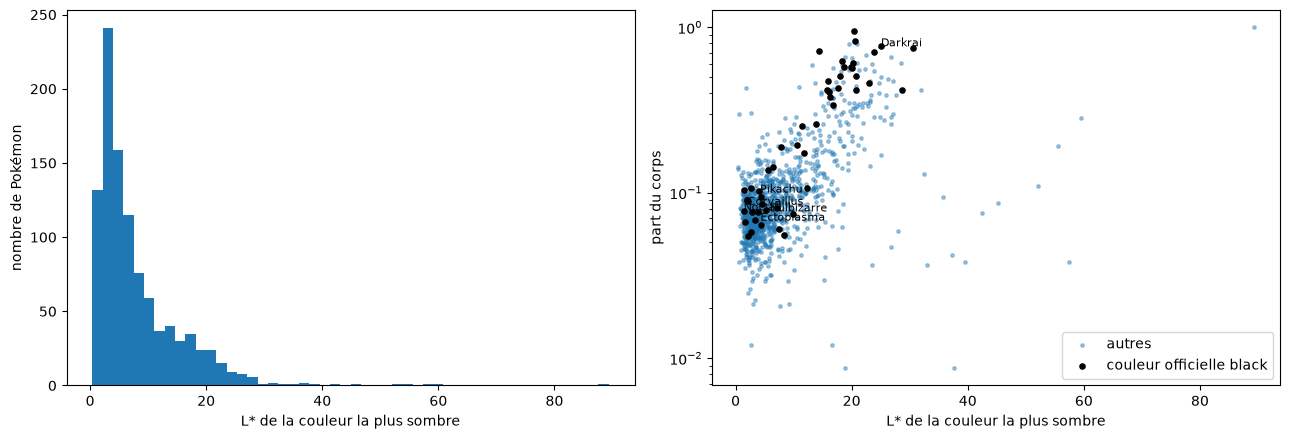

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].hist(sombre.L_sombre, bins=50)
axes[0].set(xlabel="L* de la couleur la plus sombre", ylabel="nombre de Pokémon")
noirs = sombre.couleur == "black"
axes[1].scatter(sombre.loc[~noirs, "L_sombre"], sombre.loc[~noirs, "part_sombre"], s=6, alpha=.4, label="autres")
axes[1].scatter(sombre.loc[noirs, "L_sombre"], sombre.loc[noirs, "part_sombre"], s=14, color="k", label="couleur officielle black")
for d in [197, 491, 823, 94, 1, 25]:
    axes[1].annotate(nom[d], (sombre.L_sombre[d], sombre.part_sombre[d]), fontsize=8)
axes[1].set(xlabel="L* de la couleur la plus sombre", ylabel="part du corps", yscale="log")
axes[1].legend(); plt.tight_layout(); plt.show()

In [17]:
# les Pokémon de couleur officielle noire : à quoi ressemble leur couleur la plus sombre ?
sombre[noirs].sort_values("part_sombre", ascending=False).round(3)

,L_sombre,part_sombre,nom_fr,couleur
dex,,,,
838,20.467,0.952,Wagomine,black
644,20.507,0.822,Zekrom,black
491,25.049,0.766,Darkrai,black
228,30.629,0.749,Malosse,black
800,14.373,0.713,Necrozma,black
799,23.904,0.711,Engloutyran,black
1015,18.385,0.624,Fortusimia,black
608,20.160,0.608,Mélancolux,black
609,19.825,0.575,Lugulabre,black


La couleur la plus sombre de chaque Pokémon est en général **presque noire** (L\* médian de 5, alors que 0 c'est le noir parfait) et elle couvre peu du corps (8 % en médiane). Ça ressemble beaucoup à un contour.

Sur le nuage de points, les Pokémon de couleur officielle noire sont de deux sortes : certains sont tout en bas à gauche comme les autres (couleur très sombre, petite part), d'autres sont plus haut et plus à droite (couleur sombre mais pas noire, grande part). On regarde quelques palettes en détail pour comprendre.

In [18]:
def detail(d):
    r = resultats[d]
    L = rgb_vers_lab(r["centres"])[:, 0]
    return pd.DataFrame({"couleur": ["#{:02x}{:02x}{:02x}".format(*np.round(c).astype(int)) for c in r["centres"]],
                         "L*": L.round(1), "part": r["parts"].round(3)})

for d in [1, 6, 197, 491, 229, 644]:
    print(nom[d]); print(detail(d).to_string()); print()

Bulbizarre
   couleur    L*   part
0  #7dad91  66.9  0.869
1  #0f1412   5.9  0.077
2  #f2f3f8  96.0  0.028
3  #a95c69  48.4  0.026

Dracaufeu
   couleur    L*   part
0  #d28c58  64.4  0.445
1  #327e8d  48.9  0.274
2  #e6d5a0  85.3  0.196
3  #171613   7.2  0.046
4  #684730  33.2  0.039

Noctali
   couleur    L*   part
0  #414649  29.5  0.815
1  #d5b473  75.0  0.107
2  #050505   1.4  0.078

Darkrai
   couleur    L*   part
0  #3c3b3c  25.0  0.766
1  #d3d2d0  84.2  0.171
2  #b6675e  52.3  0.063

Démolosse
   couleur    L*   part
0  #544847  31.9  0.602
1  #bfb2ad  73.4  0.218
2  #181314   6.4  0.143
3  #ca7b5b  59.3  0.037

Zekrom
   couleur    L*   part
0  #303134  20.5  0.822
1  #516467  41.0  0.169
2  #5ec2d9  73.6  0.008



On voit plusieurs cas :
- chez Bulbizarre et Dracaufeu, le contour est une couleur presque noire (L\* de 6 et 7) qui couvre 5 à 8 % du corps ;
- chez **Noctali**, le corps « noir » est en fait un **gris très foncé** (L\* autour de 29) qui couvre 82 % du corps, et le contour est **une couleur à part**, encore plus noire (L\* de 1) et qui ne couvre que 8 %. Donc on peut enlever le contour sans toucher à son noir ;
- chez **Darkrai** et **Zekrom**, il n'y a pas de couleur très sombre à part : le contour est fondu dans leur corps sombre (L\* de 25 et 21, 77 % et 82 % du corps) ;
- chez **Démolosse**, la couleur la plus sombre (L\* de 6) couvre 14 % du corps, deux fois plus qu'un trait normal : le contour s'est sans doute mélangé avec une partie de son pelage noir.

Donc un contour, c'est une couleur **très sombre** (beaucoup plus que le corps des Pokémon noirs) et qui couvre **peu** du corps. On regarde jusqu'où va cette « petite part ».

866 Pokémon ont une couleur plus sombre que L* = 15


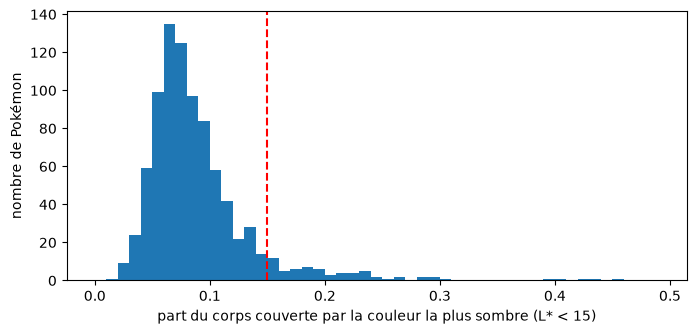

,L_sombre,part_sombre,nom_fr,couleur
dex,,,,
800,14.373,0.713,Necrozma,black
262,13.140,0.589,Grahyèna,gray
794,13.696,0.458,Mouscoto,red
993,10.926,0.433,Têtes-de-Fer,blue
366,1.776,0.430,Coquiperl,blue
203,14.638,0.405,Girafarig,yellow
92,14.764,0.392,Fantominus,purple
362,2.643,0.301,Oniglali,gray
140,0.592,0.297,Kabuto,brown


In [19]:
# les Pokémon dont la couleur la plus sombre est très sombre : quelle part du corps couvre-t-elle ?
tres_sombre = sombre[sombre.L_sombre < 15]
print(len(tres_sombre), "Pokémon ont une couleur plus sombre que L* = 15")
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(tres_sombre.part_sombre, bins=np.arange(0, 0.5, 0.01))
ax.axvline(0.15, color="red", ls="--")
ax.set(xlabel="part du corps couverte par la couleur la plus sombre (L* < 15)", ylabel="nombre de Pokémon")
plt.show()
tres_sombre[tres_sombre.part_sombre > 0.15].sort_values("part_sombre", ascending=False).head(15).round(3)

866 Pokémon ont une couleur plus sombre que L\* = 15. Pour la grande majorité, elle couvre entre 4 et 12 % du corps, avec un pic vers 6-8 % : c'est l'épaisseur normale du trait. Au-delà de 15 %, ça devient rare, et ce sont des Pokémon qui ont vraiment de grandes zones noires (le dessous de Kabuto, le visage d'Oniglali, la coquille de Coquiperl, le pelage de Grahyèna…).

Du coup on décide de la règle suivante : **la couleur la plus sombre d'un Pokémon est un contour si elle est plus sombre que L\* = 15 et si elle couvre au plus 15 % du corps**. Dans ce cas on l'enlève et on recalcule les parts des autres couleurs sur le corps sans le contour. On met le seuil de clarté à 15 parce que les traits sont presque noirs (L\* de 1 à 10) alors que le corps des Pokémon noirs est plutôt vers 20-30. Si un Pokémon n'a pas de couleur qui remplit les deux conditions, on ne touche à rien.

In [20]:
L_CONTOUR = 15
PART_CONTOUR = 0.15

def sans_contour(r):
    L = rgb_vers_lab(r["centres"])[:, 0]
    i = np.argmin(L)
    contour = (L[i] < L_CONTOUR) and (r["parts"][i] <= PART_CONTOUR)
    garde = np.ones(len(L), bool)
    if contour:
        garde[i] = False
    centres = r["centres"][garde]
    parts = r["parts"][garde] / r["parts"][garde].sum()   # on recalcule les parts sur le corps sans le contour
    pix = r["X"][np.isin(r["groupe_pixel"], np.where(garde)[0])]
    return centres, parts, pix, contour

nettoye = {d: sans_contour(r) for d, r in resultats.items()}
a_contour = pd.Series({d: v[3] for d, v in nettoye.items()})
print("Pokémon dont on a enlevé un contour :", a_contour.sum(), "sur", len(a_contour))

Pokémon dont on a enlevé un contour : 797 sur 1025


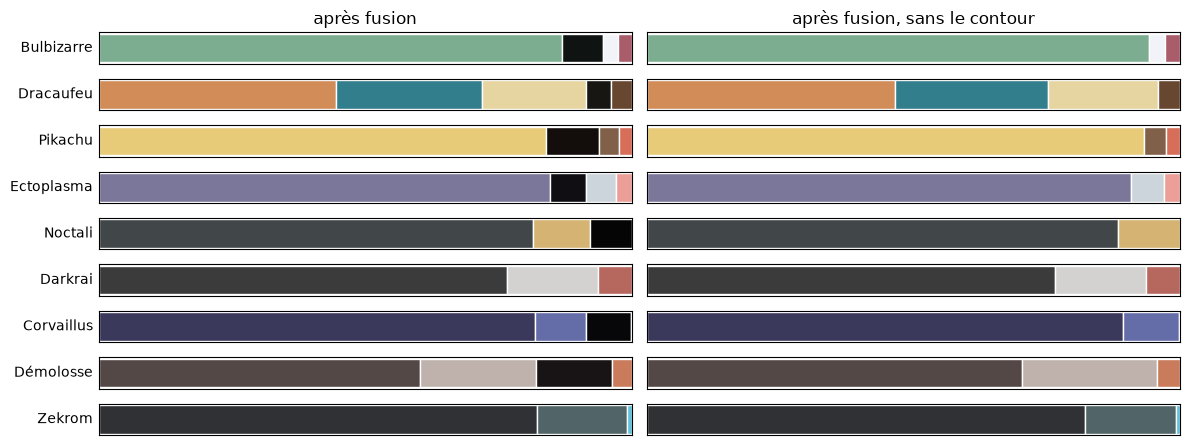

In [21]:
# avant / après sur quelques exemples, dont des Pokémon noirs
ex = [1, 6, 25, 94, 197, 491, 823, 229, 644]
fig, axes = plt.subplots(len(ex), 2, figsize=(12, 0.45 * len(ex) + 0.5))
for ligne, d in zip(axes, ex):
    dessine(ligne[0], resultats[d]["centres"], resultats[d]["parts"])
    dessine(ligne[1], nettoye[d][0], nettoye[d][1])
    ligne[0].set_ylabel(nom[d], rotation=0, ha="right", va="center")
    for ax in ligne: ax.set_xticks([])
axes[0, 0].set_title("après fusion"); axes[0, 1].set_title("après fusion, sans le contour")
plt.tight_layout(); plt.show()

On enlève un contour chez **797 Pokémon sur 1 025**. Sur les exemples, Bulbizarre, Dracaufeu, Pikachu et Ectoplasma perdent juste leur trait noir et gardent toutes leurs vraies couleurs (le rouge des joues de Pikachu, le brun de la flamme de Dracaufeu…). Noctali et Corvaillus perdent leur contour mais gardent leur grande zone sombre (le gris foncé de Noctali, le bleu nuit de Corvaillus). Démolosse perd sa couleur la plus sombre (14 % du corps, juste sous le seuil), mais garde son pelage gris-brun foncé, qui couvre 70 % du corps. Darkrai et Zekrom ne changent pas, puisque leur couleur sombre est une vraie couleur du corps.

In [22]:
# vérification sur les 51 Pokémon de couleur officielle noire : est-ce qu'il leur reste une couleur sombre ?
verif = pd.DataFrame({
    "contour_enleve": a_contour,
    "L_min_apres": pd.Series({d: rgb_vers_lab(v[0])[:, 0].min() for d, v in nettoye.items()}),
    "part_sombre_apres": pd.Series({d: v[1][rgb_vers_lab(v[0])[:, 0] < 35].sum() for d, v in nettoye.items()}),
}).join(table[["nom_fr", "couleur"]])
vn = verif[verif.couleur == "black"]
print("contour enlevé :", vn.contour_enleve.sum(), "sur", len(vn))
print("gardent une couleur sombre (L* < 35) d'au moins 5 % du corps :", (vn.part_sombre_apres >= 0.05).sum(), "sur", len(vn))
vn[vn.part_sombre_apres < 0.05].round(3)

contour enlevé : 24 sur 51
gardent une couleur sombre (L* < 35) d'au moins 5 % du corps : 39 sur 51


,contour_enleve,L_min_apres,part_sombre_apres,nom_fr,couleur
143,True,50.309,0.000,Ronflex,black
215,True,43.796,0.000,Farfuret,black
303,True,40.156,0.000,Mysdibule,black
325,True,63.579,0.000,Spoink,black
336,True,42.291,0.000,Séviper,black
353,True,51.316,0.000,Polichombr,black
354,True,53.861,0.000,Branette,black
355,True,28.589,0.025,Skelénox,black
441,True,36.038,0.000,Pijako,black
446,True,51.928,0.000,Goinfrex,black


Sur les 51 Pokémon de couleur officielle noire, on a enlevé un contour chez 24, et **39 gardent une couleur sombre** qui couvre au moins 5 % du corps.

Les 12 qui n'en gardent pas sont des Pokémon dont le « noir » officiel n'est pas la couleur qui couvre le plus de surface : Ronflex est surtout bleu-vert et crème, Goinfrex aussi, Spoink est gris, Branette et Polichombr sont gris-bleu, Pijako est multicolore. Là c'est normal.

**Attention aux cas limites.** Avant qu'on donne à chaque Pokémon son propre tirage de pixels (partie 1), **Malosse** était une vraie erreur : son pelage noir s'était mélangé avec le contour et couvrait 14,5 % du corps, juste sous notre seuil de 15 %, donc on l'enlevait alors qu'il fallait le garder. Avec le tirage actuel, son pelage forme une couleur à part (75 % du corps) et il est bien traité. Ça montre qu'un Pokémon proche des seuils peut basculer d'un côté ou de l'autre selon les pixels tirés : pour la grande majorité, la règle est stable, mais quelques Pokémon noirs (Malosse, Démolosse…) restent fragiles. On accepte ce risque : baisser le seuil ferait garder le contour de beaucoup d'autres Pokémon.

### Ce qu'on a fait et pourquoi

**1. Repérer le contour avec deux critères : clarté et surface.** Le trait noir des dessins n'est pas une couleur du Pokémon, mais on ne pouvait pas enlever tout le noir, sinon les Pokémon vraiment noirs perdaient leur couleur. On a donc regardé, pour chaque Pokémon, sa couleur la plus sombre avec deux informations : sa clarté L\* (est-ce que c'est presque noir ?) et la part du corps qu'elle couvre (est-ce que c'est un trait fin ou une grande zone ?).

**2. L'histogramme et le nuage de points pour placer les seuils.** L'histogramme de la clarté montre que la couleur la plus sombre est presque toujours quasi noire. Le nuage clarté × part du corps (avec la part en échelle log, parce que les parts vont de très petites à presque tout le corps), avec les Pokémon officiellement noirs en noir, montre les deux cas à séparer. Ensuite l'histogramme des parts chez les Pokémon très sombres fait apparaître un pic qui correspond à l'épaisseur normale du trait : on a mis le seuil de part juste après ce pic.

**3. Regarder des palettes en détail.** Avant de fixer la règle, on a regardé les palettes de quelques Pokémon choisis exprès (des Pokémon normaux et des Pokémon noirs) pour comprendre ce qui se passe vraiment, au lieu de se fier qu'aux graphiques.

**4. Vérifier la règle sur les Pokémon noirs.** Après avoir enlevé les contours, on a contrôlé que les Pokémon de couleur officielle noire gardent bien une couleur sombre, et on a regardé un par un ceux qui n'en gardent pas. C'est comme ça qu'on a repéré les cas limites (Malosse, qui changeait de côté selon les pixels tirés), plutôt que de les découvrir plus tard dans une analyse.

## 6. Les variables de couleur de chaque Pokémon

Maintenant qu'on a la palette de chaque Pokémon sans le contour, on peut calculer les variables. Il reste à décider à partir de quelle part du corps une couleur compte comme « importante ». On regarde ce que donne le nombre de couleurs avec plusieurs seuils.

In [23]:
for s in [0.02, 0.05, 0.10]:
    nb = pd.Series({d: int((v[1] >= s).sum()) for d, v in nettoye.items()})
    print(f"seuil {s:.0%} : médiane {nb.median():.0f} couleurs, de {nb.min()} à {nb.max()} ; répartition {nb.value_counts().sort_index().to_dict()}")

seuil 2% : médiane 4 couleurs, de 1 à 7 ; répartition {1: 12, 2: 136, 3: 339, 4: 301, 5: 176, 6: 56, 7: 5}
seuil 5% : médiane 3 couleurs, de 1 à 7 ; répartition {1: 52, 2: 265, 3: 388, 4: 206, 5: 89, 6: 22, 7: 3}
seuil 10% : médiane 2 couleurs, de 1 à 6 ; répartition {1: 106, 2: 415, 3: 362, 4: 116, 5: 22, 6: 4}


Le seuil change beaucoup le résultat :
- à **2 %**, on compte jusqu'à 8 couleurs, mais on compte aussi des petits détails (les yeux, une griffe, un reflet) ;
- à **10 %**, 101 Pokémon n'ont plus qu'une couleur et 418 en ont deux : on perd des couleurs secondaires bien visibles sur les dessins ;
- à **5 %**, on a entre 1 et 7 couleurs, 3 en médiane, ce qui correspond à ce qu'on voit à l'œil sur les exemples.

On choisit donc **5 %** : une couleur compte comme « importante » si elle couvre au moins 5 % du corps (sans le contour).

In [24]:
PART_MIN = 0.05

lignes = []
for d, (centres, parts, pix, contour) in nettoye.items():
    r, g, b = centres[0]
    h, s, v = colorsys.rgb_to_hsv(r / 255, g / 255, b / 255)
    hsv = np.array([colorsys.rgb_to_hsv(*(p / 255)) for p in pix])
    lignes.append({
        "dex": d,
        "nb_couleurs": int((parts >= PART_MIN).sum()),
        "dom_r": round(r), "dom_v": round(g), "dom_b": round(b),
        "dom_hex": "#{:02x}{:02x}{:02x}".format(round(r), round(g), round(b)),
        "dom_teinte": round(h * 360, 1), "dom_saturation": round(s, 3), "dom_luminosite": round(v, 3),
        "dom_part": round(parts[0], 3),
        "saturation_moyenne": round(hsv[:, 1].mean(), 3), "luminosite_moyenne": round(hsv[:, 2].mean(), 3),
        "palette": ";".join("#{:02x}{:02x}{:02x}:{:.3f}".format(*np.round(c).astype(int), p) for c, p in zip(centres, parts)),
    })
coul = pd.DataFrame(lignes).set_index("dex")
coul.head()

,nb_couleurs,dom_r,dom_v,dom_b,dom_hex,dom_teinte,dom_saturation,dom_luminosite,dom_part,saturation_moyenne,luminosite_moyenne,palette
dex,,,,,,,,,,,,
1,1,125,173,145,#7dad91,145.1,0.281,0.680,0.941,0.286,0.691,#7dad91:0.941;#f2f3f8:0.030;#a95c69:0.028
2,3,119,167,154,#77a79a,163.0,0.287,0.655,0.560,0.369,0.669,#77a79a:0.560;#4c8898:0.296;#d18490:0.145
3,3,93,144,134,#5d9086,167.7,0.353,0.565,0.551,0.378,0.564,#5d9086:0.551;#333431:0.214;#cf7479:0.186;#e2c...
4,2,213,159,118,#d59f76,25.5,0.446,0.836,0.650,0.380,0.839,#d59f76:0.650;#eadac5:0.266;#66453c:0.041;#e17...
5,2,204,108,91,#cc6c5b,8.9,0.553,0.802,0.691,0.460,0.808,#cc6c5b:0.691;#d9c1b3:0.213;#f8cf6c:0.037;#553...


In [25]:
coul[["nb_couleurs", "dom_part", "dom_saturation", "dom_luminosite", "saturation_moyenne", "luminosite_moyenne"]].describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
nb_couleurs,1025.0,3.091,1.115,1.000,2.000,3.000,4.000,7.000
dom_part,1025.0,0.589,0.178,0.192,0.461,0.563,0.704,1.000
dom_saturation,1025.0,0.285,0.208,0.000,0.106,0.253,0.440,0.990
dom_luminosite,1025.0,0.689,0.221,0.030,0.544,0.752,0.871,0.996
saturation_moyenne,1025.0,0.302,0.141,0.014,0.195,0.298,0.404,0.800
luminosite_moyenne,1025.0,0.691,0.138,0.227,0.597,0.700,0.799,0.961


Sans le contour, un Pokémon a en moyenne **3,1 couleurs importantes** (médiane 3, de 1 à 7), et sa couleur dominante couvre en moyenne 59 % du corps. Comme le contour couvre au plus 15 % du corps, ce n'est jamais la couleur dominante : enlever le contour ne change pas la couleur dominante, ça change surtout le nombre de couleurs et la luminosité moyenne (on a retiré beaucoup de pixels noirs).

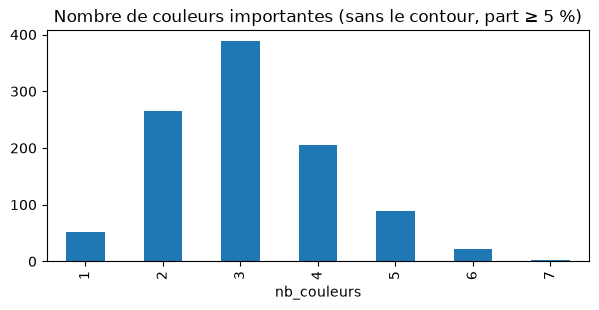

In [26]:
coul["nb_couleurs"].value_counts().sort_index().plot.bar(figsize=(7, 3), title="Nombre de couleurs importantes (sans le contour, part ≥ 5 %)")
plt.show()

In [27]:
tmp = coul.join(nom)
print(tmp.sort_values(["nb_couleurs", "dom_part"], ascending=[True, False]).head(8)[["nom_fr", "nb_couleurs", "dom_part"]])
print(tmp.sort_values(["nb_couleurs", "dom_part"], ascending=[False, True]).head(8)[["nom_fr", "nb_couleurs", "dom_part"]])

         nom_fr  nb_couleurs  dom_part
dex                                   
51   Triopikeur            1     1.000
151         Mew            1     1.000
633     Solochi            1     1.000
868       Crèmy            1     1.000
980   Terraiste            1     0.995
132   Métamorph            1     0.994
564   Carapagos            1     0.991
489      Phione            1     0.990
          nom_fr  nb_couleurs  dom_part
dex                                    
910    Crocogril            7     0.228
658    Amphinobi            7     0.255
911   Flâmigator            7     0.260
1021  Ire-Foudre            6     0.192
720        Hoopa            6     0.230
1007    Koraidon            6     0.237
739   Crabagarre            6     0.269
178         Xatu            6     0.271


Les Pokémon à une seule couleur sont des Pokémon « d'un bloc » : Mew, Crèmy, Terraiste, Métamorph, Solochi, Phione. Les plus chargés (7 couleurs) sont Crocogril, Amphinobi et Flâmigator, suivis de 22 Pokémon à 6 couleurs (Xatu, Hoopa, Koraidon, Miraidon, Feu-Perçant…).

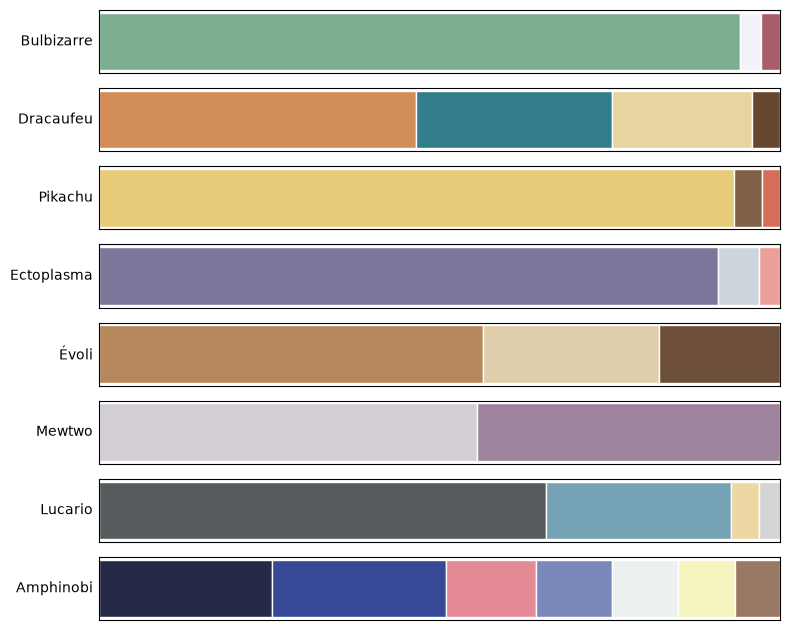

In [28]:
exemples = [1, 6, 25, 94, 133, 150, 448, 658]
fig, axes = plt.subplots(len(exemples), 1, figsize=(8, 0.8 * len(exemples)))
for ax, d in zip(axes, exemples):
    dessine(ax, nettoye[d][0], nettoye[d][1])
    ax.set_ylabel(nom[d], rotation=0, ha="right", va="center")
    ax.set_xticks([])
plt.tight_layout(); plt.show()

### Ce qu'on a fait et pourquoi

**1. Choisir le seuil de « couleur importante » en comparant plusieurs valeurs.** On a calculé le nombre de couleurs avec trois seuils de part du corps et regardé la répartition obtenue. On a gardé celui qui donne des résultats qui collent à ce qu'on voit sur les dessins : un seuil trop bas compte les yeux et les reflets, un seuil trop haut fait disparaître des couleurs secondaires bien visibles.

**2. Des variables en HSV.** Pour décrire la couleur dominante et l'ensemble du Pokémon, on a utilisé le système HSV (teinte, saturation, luminosité) en plus du code RGB. Le HSV est plus facile à interpréter : « plus saturé » ou « plus lumineux » veut dire quelque chose, alors qu'une hausse du « vert » en RGB ne dit pas grand-chose. La saturation et la luminosité moyennes sont calculées sur les pixels (sans le contour), pas sur les centres, pour tenir compte de la surface de chaque couleur.

**3. Le diagramme en barres du nombre de couleurs.** Le nombre de couleurs est un petit nombre entier, donc un diagramme en barres (une barre par valeur) est plus lisible qu'un histogramme.

## 7. Ramener la couleur dominante à une famille de couleur

Pour comparer avec la couleur officielle de PokéAPI, il faut transformer la couleur dominante (un code RGB) en un des **10 noms** utilisés par PokéAPI : black, blue, brown, gray, green, pink, purple, red, white, yellow.

On passe par le système **HSV** (teinte, saturation, luminosité), qui est plus proche de la façon dont on décrit une couleur avec des mots. Il n'existe pas de règle officielle pour passer d'un code couleur à un nom, donc on décide de faire nos propres seuils, simples, en suivant le bon sens :
- très sombre (luminosité < 0,25) → black ;
- peu saturée (saturation < 0,2) → white si claire, gray sinon ;
- les rouges et magentas clairs et pas trop saturés → pink ;
- sinon on regarde la teinte (l'angle sur le cercle des couleurs : rouge vers 0°, jaune vers 60°, vert vers 120°, bleu vers 240°…), et les teintes orangées sombres deviennent brown.

C'est une approximation : on verra en comparant avec la couleur officielle où elle se trompe.

In [29]:
def famille(h, s, v):
    h = h * 360
    if v < 0.25:
        return "black"
    if s < 0.2:
        return "white" if v > 0.8 else "gray"
    if (h >= 300 or h < 15) and s < 0.55 and v > 0.7:
        return "pink"
    if h < 15 or h >= 345:
        return "brown" if v < 0.5 else "red"
    if h < 40:
        return "brown" if (v < 0.7 or s < 0.5) else "red"
    if h < 70:
        return "brown" if v < 0.5 else "yellow"
    if h < 170:
        return "green"
    if h < 260:
        return "blue"
    if h < 290:
        return "purple"
    return "pink"

coul["famille_dominante"] = [famille(h / 360, s, v) for h, s, v in coul[["dom_teinte", "dom_saturation", "dom_luminosite"]].values]
coul["famille_dominante"].value_counts()

famille_dominante
white     197
gray      180
blue      175
brown      95
yellow     88
green      84
red        69
pink       64
black      52
purple     21
Name: count, dtype: int64

White, gray et blue sont les familles dominantes les plus fréquentes (197, 180 et 175 Pokémon). Beaucoup de Pokémon ont un corps pâle ou grisé, et les dessins ont des zones claires (reflets). Purple est presque absent (21).

In [30]:
pd.crosstab(table["couleur"], coul["famille_dominante"], margins=True)

famille_dominante,black,blue,brown,gray,green,pink,purple,red,white,yellow,All
couleur,,,,,,,,,,,
black,17,7,0,24,0,0,0,0,3,0,51
blue,8,110,2,16,1,1,0,2,28,2,170
brown,3,0,69,28,0,3,0,10,20,14,147
gray,6,12,1,59,1,1,1,0,22,4,107
green,2,12,6,10,72,1,1,4,14,8,130
pink,1,2,2,3,1,26,2,2,19,2,60
purple,3,16,0,21,3,12,17,0,15,0,87
red,7,7,6,5,0,15,0,40,7,10,97
white,1,6,1,10,3,2,0,2,61,2,88


In [31]:
accord = (table["couleur"] == coul["famille_dominante"]).mean()
print("même famille que la couleur officielle :", round(accord, 3))
(table["couleur"] == coul["famille_dominante"]).groupby(table["couleur"]).mean().sort_values().round(2)

même famille que la couleur officielle : 0.504


couleur
purple    0.20
black     0.33
red       0.41
pink      0.43
brown     0.47
yellow    0.52
gray      0.55
green     0.55
blue      0.65
white     0.69
dtype: float64

La couleur dominante calculée tombe dans la même famille que la couleur officielle pour **50 %** des Pokémon seulement. Ça marche bien pour white (69 %) et blue (65 %), très mal pour purple (20 %) et black (33 %). Les violets officiels sont souvent classés blue, gray ou pink chez nous, et les noirs officiels souvent gray : par exemple le corps de Noctali est un gris très foncé (luminosité 0,29), juste au-dessus de notre seuil de 0,25 pour black.

In [32]:
# quelques désaccords pour comprendre
des = coul.join(table[["nom_fr", "couleur"]])
des = des[des.couleur != des.famille_dominante]
des.sample(10, random_state=SEED)[["nom_fr", "couleur", "famille_dominante", "dom_hex", "dom_part"]]

,nom_fr,couleur,famille_dominante,dom_hex,dom_part
dex,,,,,
794,Mouscoto,red,black,#2c201e,0.458
773,Silvallié,gray,white,#ecf0f4,0.465
462,Magnézone,gray,blue,#5a6b7d,0.319
967,Motorizard,green,gray,#46554e,0.608
139,Amonistar,blue,white,#d9d2b6,0.478
35,Mélofée,pink,white,#f0cad0,0.959
674,Pandespiègle,white,gray,#5a5a62,0.514
611,Incisache,green,gray,#6b6a6e,0.530
669,Flabébé,white,pink,#db7570,0.493


Sur les exemples, deux raisons reviennent. D'abord nos seuils HSV : un rose très pâle comme Mélofée devient « white », un gris bleuté comme Magnézone devient « blue » (et hors de cet échantillon, un violet pâle comme Mentali devient « white », Nidoking devient « pink »). Ensuite, la couleur officielle n'est pas toujours la couleur qui prend le plus de place sur le dessin : Amonistar est « blue » officiellement alors que sa plus grande zone est sa coquille crème, et Mouscoto est « red » alors que sa plus grande zone est sombre.

Les deux mesures ne disent donc pas la même chose : l'officielle, c'est la couleur « d'identité » choisie par les jeux ; la nôtre, c'est la couleur qui couvre le plus de surface. On garde les deux dans la suite, chacune pour ce qu'elle mesure.

### Ce qu'on a fait et pourquoi

**1. Des seuils HSV faits à la main.** Pour comparer avec la couleur officielle, il fallait transformer un code couleur en un des 10 noms de PokéAPI. Il n'existe pas de règle officielle, alors on a écrit des règles simples sur la teinte, la saturation et la luminosité. On a préféré des règles qu'on peut lire et expliquer plutôt qu'un modèle appris, parce qu'on n'a pas de « bonne réponse » fiable pour l'entraîner : la couleur officielle ne mesure pas la même chose que la nôtre.

**2. Le tableau croisé et le taux d'accord par couleur.** On a croisé la couleur officielle et notre famille dominante, et calculé le taux d'accord pour chaque couleur officielle. Le taux global seul ne suffisait pas : il cache que certaines couleurs marchent bien et d'autres très mal.

**3. Lire des désaccords au hasard.** On a tiré des désaccords au hasard (graine fixe) pour comprendre d'où ils viennent, plutôt que de regarder seulement les plus gros. Ça nous a montré que ce n'est pas qu'un problème de seuils : les deux mesures ne disent pas la même chose, donc on garde les deux.

## 8. Les couleurs selon la génération

            nb_couleurs  saturation_moyenne  luminosite_moyenne
generation                                                     
1                  2.61                0.28                0.74
2                  2.89                0.33                0.72
3                  2.73                0.27                0.76
4                  3.05                0.31                0.67
5                  2.98                0.28                0.66
6                  3.36                0.31                0.69
7                  3.57                0.28                0.67
8                  3.44                0.33                0.63
9                  3.67                0.36                0.66


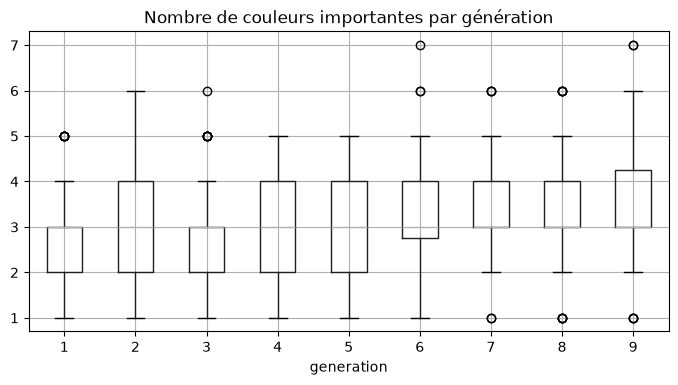

In [33]:
g = coul.join(table["generation"])
print(g.groupby("generation")[["nb_couleurs", "saturation_moyenne", "luminosite_moyenne"]].mean().round(2))
g.boxplot(column="nb_couleurs", by="generation", figsize=(8, 4))
plt.suptitle(""); plt.title("Nombre de couleurs importantes par génération"); plt.show()

Le nombre de couleurs augmente au fil des générations : **2,6 en moyenne en génération 1**, autour de **3,6-3,7 en générations 7 et 9**. La saturation moyenne monte un peu (0,28 en génération 1, 0,36 en génération 9) et la luminosité baisse (0,74 en génération 1, entre 0,63 et 0,69 à partir de la génération 4). Les Pokémon récents sont donc un peu plus chargés en couleurs, mais les écarts restent petits par rapport à la dispersion qu'on voit dans les boîtes. On testera ça proprement dans le notebook sur la conception.

### Ce qu'on a fait et pourquoi

On a comparé les générations avec la **moyenne par génération** et une **boîte à moustaches** du nombre de couleurs. La moyenne donne la tendance, et la boîte montre en plus la dispersion dans chaque génération : c'est elle qui permet de voir que les écarts entre générations sont petits par rapport aux différences entre Pokémon d'une même génération. On n'a pas fait de test ici : la question « est-ce que le design change avec les générations ? » est traitée proprement dans le notebook 06.

## 9. Export\n\nOn enregistre une ligne par Pokémon avec ses variables de couleur (sans le contour), pour les analyses suivantes (conception, réseau).

In [34]:
coul.to_csv(OUT / "couleurs_sprites.csv")
print("écrit :", OUT / "couleurs_sprites.csv", coul.shape)

écrit : ../data/processed/couleurs_sprites.csv (1025, 13)
